<a href="https://colab.research.google.com/github/ueeeahh/sam2/blob/main/dumptruck_pose_depth.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Roboflow 4점 키포인트 → YOLO-pose → 꼭짓점 → Depth (261011)
흐름: Roboflow export → 라벨 점검(점 순서) → YOLO-pose 학습 → test 픽셀 오차 → 전체 추론 → Homography/흙 영역 → Depth 굴곡·림 대비 높이

**준비물**
- Roboflow v2 (Resize 없음, Augmentation 없음) → YOLOv8 → zip 다운로드
- 드라이브 `capstone/yolo_data/pose_rf_v2/` 에 zip 그대로 업로드
- Colab: 런타임 → 런타임 유형 변경 → **GPU**

**드라이브 구조**
```
capstone/
 ├ images/                 원본 사진
 ├ yolo_data/pose_rf_v2/   Roboflow zip
 ├ yolo/pose_261011/       학습 결과 (자동 생성)
 └ outputs/                꼭짓점 json, depth 특징 csv (자동 생성)
```

In [1]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q ultralytics

import os, glob, yaml, json
import numpy as np, cv2, pandas as pd, matplotlib.pyplot as plt
from PIL import Image

BASE = '/content/drive/MyDrive/capstone'
ZIP  = f'{BASE}/yolo_data/pose_rf_v2/' + 'Dump Truck Bed Keypoints.v2i.yolov8.zip'   # ← 실제 zip 파일 이름으로 수정
IMG_ALL = f'{BASE}/images'                                # 꼭짓점 뽑을 전체 사진 폴더
OUT  = f'{BASE}/outputs'; os.makedirs(OUT, exist_ok=True)
RUN  = 'pose_261011'                                      # 학습 결과 폴더 이름
CAB_ON_RIGHT = True          # 사진에서 운전석이 오른쪽이면 True
BED_L, BED_W = 5.0, 2.3      # 적재함 내치수(m) — 실제 값으로
NAMES = ['front-far', 'front-near', 'rear-near', 'rear-far']   # 팀이 정한 점 순서 이름으로 수정

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 8.6 MB/s eta 0:00:00


## 1. Roboflow zip 풀기 + data.yaml 정리

In [2]:
ROOT = '/content/rf_pose'
!rm -rf {ROOT} && unzip -q -o "{ZIP}" -d {ROOT}
!ls {ROOT}
cfg = yaml.safe_load(open(f'{ROOT}/data.yaml'))
print(cfg)                                   # kpt_shape, flip_idx, names 확인
# Ultralytics가 경로를 못 찾는 경우가 많아서 절대경로로 다시 씀
cfg.update(path=ROOT, train='train/images', val='valid/images', test='test/images')
cfg['flip_idx'] = list(range(cfg['kpt_shape'][0]))   # 어차피 fliplr=0으로 학습
yaml.safe_dump(cfg, open(f'{ROOT}/data_abs.yaml', 'w'))
for s in ['train', 'valid', 'test']:
    print(s, len(glob.glob(f'{ROOT}/{s}/images/*')))

data.yaml  README.roboflow.txt	test  train  valid
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'kpt_shape': [4, 3], 'flip_idx': [0, 1, 2, 3], 'nc': 1, 'names': ['truck_bed'], 'roboflow': {'workspace': 'shin-yujeong-s-workspace', 'project': 'dump-truck-bed-keypoints', 'version': 2, 'license': 'Private', 'url': 'https://app.roboflow.com/shin-yujeong-s-workspace/dump-truck-bed-keypoints/2'}}
train 74
valid 21
test 10


## 2. 라벨 점검 — 점 순서가 사람마다 일관적인가
pose 라벨 한 줄: `cls cx cy w h  x1 y1 v1  x2 y2 v2 ...` (정규화 좌표, v: 0=없음 1=가려짐 2=보임)

In [3]:
def read_pose(lbl, W, H):
    v = np.array(open(lbl).read().split(), float)
    k = v[5:].reshape(-1, 3)
    return k[:, :2] * [W, H], k[:, 2]

def geo_order(pts):
    """점 4개를 기하학적으로 정렬: 앞-먼, 앞-가까, 뒤-가까, 뒤-먼 (앞=운전석 쪽)"""
    c = pts.mean(0)
    isfront = pts[:, 0] > c[0] if CAB_ON_RIGHT else pts[:, 0] < c[0]
    if isfront.sum() != 2: return None
    f = np.where(isfront)[0]; r = np.where(~isfront)[0]
    f = f[np.argsort(pts[f, 1])]; r = r[np.argsort(pts[r, 1])]
    return np.array([f[0], f[1], r[1], r[0]])

rows = []
for s in ['train', 'valid', 'test']:
    for ip in glob.glob(f'{ROOT}/{s}/images/*'):
        st = os.path.splitext(os.path.basename(ip))[0]
        lp = f'{ROOT}/{s}/labels/{st}.txt'
        if not os.path.exists(lp): continue
        H, W = cv2.imread(ip).shape[:2]
        pts, vis = read_pose(lp, W, H)
        g = geo_order(pts)
        rows.append(dict(split=s, file=st, W=W, H=H, img=ip,
                         order_ok=g is not None and (g == np.arange(4)).all(),
                         hidden=int((vis < 2).sum()), geo=g))
lab = pd.DataFrame(rows)
print(lab.groupby(['W', 'H']).size())
print('순서가 기준과 다른 라벨:', (~lab.order_ok).sum(), '/', len(lab))
print(lab[~lab.order_ok][['split', 'file', 'geo']].head(20))

W    H  
720  480    105
dtype: int64
순서가 기준과 다른 라벨: 1 / 105
    split                                               file   geo
47  train  20260727_00002_jpg.rf.17f4ed3323899e16e72f4318...  None


/tmp/ipykernel_704/1913943301.py:8: RuntimeWarning: Mean of empty slice.
  c = pts.mean(0)
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:139: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


In [4]:
# 키포인트가 없는(빈) 라벨 찾아서 사진·라벨 함께 제외
for s in ['train', 'valid', 'test']:
    for lp in glob.glob(f'{ROOT}/{s}/labels/*.txt'):
        if len(open(lp).read().split()) < 5 + 4 * 3:
            st = os.path.splitext(os.path.basename(lp))[0]
            for ip in glob.glob(f'{ROOT}/{s}/images/{st}.*'):
                os.remove(ip)
            os.remove(lp)
            print('제외:', s, st)

제외: train 20260727_00002_jpg.rf.17f4ed3323899e16e72f43184496cf0b


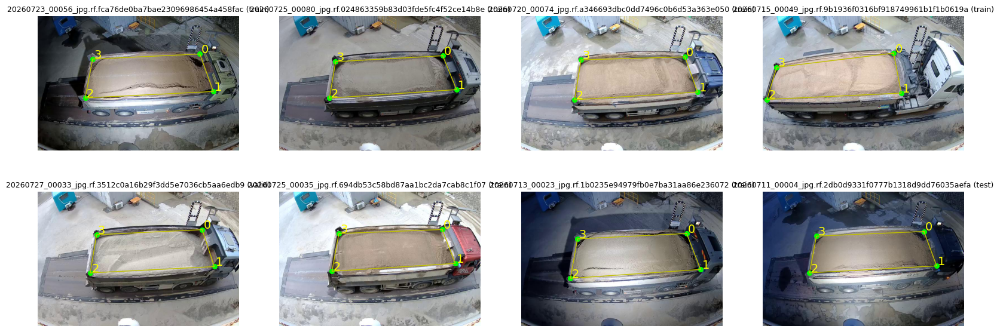

In [5]:
# 몇 장 눈으로 확인: 숫자가 NAMES 순서대로 찍혔는지
fig, ax = plt.subplots(2, 4, figsize=(20, 7))
for a, (_, r) in zip(ax.ravel(), lab.sample(8, random_state=0).iterrows()):
    im = cv2.cvtColor(cv2.imread(r.img), cv2.COLOR_BGR2RGB)
    pts, vis = read_pose(f'{ROOT}/{r.split}/labels/{r.file}.txt', r.W, r.H)
    a.imshow(im); a.plot(*np.vstack([pts, pts[:1]]).T, 'y-', lw=1)
    for i, (p, v) in enumerate(zip(pts, vis)):
        a.scatter(*p, c='lime' if v == 2 else 'red', s=30); a.text(p[0] + 5, p[1] - 5, str(i), color='yellow', fontsize=14)
    a.set_title(f'{r.file} ({r.split})', fontsize=9); a.axis('off')
plt.show()

**순서가 틀린 라벨이 있으면**: Roboflow에서 고치거나, 아래 셀로 기하 정렬해서 덮어쓰기 (트럭이 항상 같은 방향으로 서는 고정 카메라라 안전함).

In [ ]:
FIX = False
if FIX:
    for _, r in lab[~lab.order_ok & lab.geo.notna()].iterrows():
        lp = f'{ROOT}/{r.split}/labels/{r.file}.txt'
        v = np.array(open(lp).read().split(), float)
        k = v[5:].reshape(-1, 3)[r.geo]
        open(lp, 'w').write(' '.join([str(int(v[0]))] + [f'{x:.6f}' for x in v[1:5]] + [f'{x:.6f}' for x in k.ravel()]))
    print('fixed')

## 3. [n640] YOLO-pose 학습
- `fliplr=0`: 좌우반전하면 운전석이 왼쪽으로 가서 '앞/뒤' 정의가 뒤집힘. 고정 카메라라 반전 증강은 필요 없음
- 105장이라 작은 모델(n/s) + 사전학습 가중치 + 에포크 넉넉히

In [6]:
from ultralytics import YOLO
model = YOLO('yolo26n-pose.pt')        # 안 받아지면 'yolo11n-pose.pt'
model.train(data=f'{ROOT}/data_abs.yaml', epochs=150, imgsz=736, batch=8, patience=40,
            fliplr=0.0, degrees=3, translate=0.1, scale=0.3, mosaic=0.5,
            project=f'{BASE}/yolo', name=RUN, exist_ok=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rf_pose/data_abs.yaml, degrees=3, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, fr

ultralytics.utils.metrics.PoseMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b1cbaba56a0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(P)', 'F1-Confidence(P)', 'Precision-Confidence(P)', 'Recall-Confidence(P)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    

**판단 기준(720×480 기준 대략)**: 꼭짓점 평균 오차가 3~5px 이내면 사람 라벨 수준. 10px 이상이면 라벨 추가(가려진/야간 사진 위주) 필요. 특정 꼭짓점만 크면 그 점의 라벨 규칙(둥근 모서리 연장선 등)이 사람마다 달랐을 가능성.

# **n640 결과 rear-near 오차가 커서 s960 모델 추가, 앙상블 추가**

## 3-2. 새로운 모델 추가[s960]: 모델 문제인지 확인하기 위해 개선 모델 재 train

In [11]:
from ultralytics import YOLO

RUN_OLD = 'pose_261011'           # 기존 n 모델 (비교용)
RUN     = 'pose_261011_s960'      # 새 모델 이름 → 섹션 5~7도 이 이름으로 저장됨

model = YOLO('yolo26s-pose.pt')   # 안 받아지면 'yolo11s-pose.pt'
model.train(data=f'{ROOT}/data_abs.yaml', epochs=200, imgsz=960, batch=8, patience=60,
            fliplr=0.0, degrees=3, translate=0.1, scale=0.3, mosaic=0.5,
            project=f'{BASE}/yolo', name=RUN, exist_ok=True)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rf_pose/data_abs.yaml, degrees=3, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s-pose.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=pose_261011_s960, nbs=64, nms=None, opset=None, optimize=

ultralytics.utils.metrics.PoseMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b1d602cc440>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(P)', 'F1-Confidence(P)', 'Precision-Confidence(P)', 'Recall-Confidence(P)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    

In [12]:
def corner_table(weights, split='test'):
    m = YOLO(weights)
    out = []
    for _, r in lab[lab.split == split].iterrows():
        gt, _ = read_pose(f'{ROOT}/{split}/labels/{r.file}.txt', r.W, r.H)
        res = m(r.img, verbose=False)[0]
        if len(res.keypoints) == 0:
            out.append([np.nan] * 4); continue
        pred = res.keypoints.xy[res.boxes.conf.argmax()].cpu().numpy()
        out.append(np.linalg.norm(pred - gt, axis=1))
    return pd.DataFrame(out, columns=NAMES)

old = corner_table(f'{BASE}/yolo/{RUN_OLD}/weights/best.pt')
new = corner_table(f'{BASE}/yolo/{RUN}/weights/best.pt')

cmp = pd.DataFrame({'n640 평균': old.mean(), 's960 평균': new.mean(),
                    'n640 최대': old.max(),  's960 최대': new.max()}).round(1)
cmp.loc['전체'] = [old.values.mean(), new.values.mean(), old.values.max(), new.values.max()]
print(cmp.round(1))

            n640 평균  s960 평균  n640 최대  s960 최대
front-far      10.2     12.6     24.4     21.2
front-near      9.3      5.5     19.6      9.9
rear-near      21.5     13.7     26.6     28.7
rear-far       10.1     16.3     18.3     29.8
전체             12.8     12.0     26.6     29.8


## 3-3. 앙상블 추가: 두 모델 평균내서 합침 (ens)

In [13]:
m_old = YOLO(f'{BASE}/yolo/{RUN_OLD}/weights/best.pt')
m_new = YOLO(f'{BASE}/yolo/{RUN}/weights/best.pt')

def pred4(m, img):
    res = m(img, verbose=False)[0]
    return res.keypoints.xy[res.boxes.conf.argmax()].cpu().numpy() if len(res.keypoints) else None

out = []
for _, r in lab[lab.split == 'test'].iterrows():
    gt, _ = read_pose(f'{ROOT}/test/labels/{r.file}.txt', r.W, r.H)
    a, b = pred4(m_old, r.img), pred4(m_new, r.img)
    out.append(np.linalg.norm((a + b) / 2 - gt, axis=1))
ens = pd.DataFrame(out, columns=NAMES)
cmp['평균앙상블'] = list(ens.mean()) + [ens.values.mean()]
print(cmp.round(1))

            n640 평균  s960 평균  n640 최대  s960 최대  평균앙상블
front-far      10.2     12.6     24.4     21.2   10.6
front-near      9.3      5.5     19.6      9.9    6.7
rear-near      21.5     13.7     26.6     28.7   15.3
rear-far       10.1     16.3     18.3     29.8   12.7
전체             12.8     12.0     26.6     29.8   11.3


## 4. test 세트 평가 — mAP보다 **꼭짓점 픽셀 오차**가 중요
AP보다 **꼭짓점 픽셀 오차**가 중요: Homography, rim 기준 평면이 이 4점에서 나오기 때문


### (1) n640 단독 test 결과: rear-near 오차 크게 나옴

In [7]:
best = YOLO(f'{BASE}/yolo/{RUN}/weights/best.pt')
print(best.val(data=f'{ROOT}/data_abs.yaml', split='test').pose.map50)

errs = []
for _, r in lab[lab.split == 'test'].iterrows():
    gt, _ = read_pose(f'{ROOT}/test/labels/{r.file}.txt', r.W, r.H)
    res = best(r.img, verbose=False)[0]
    if len(res.keypoints) == 0: errs.append([np.nan] * 4); continue
    pred = res.keypoints.xy[res.boxes.conf.argmax()].cpu().numpy()
    errs.append(np.linalg.norm(pred - gt, axis=1))
errs = pd.DataFrame(errs, columns=NAMES, index=lab[lab.split == 'test'].file)
print(errs.describe().round(1))      # 단위: px (원본 해상도)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-pose summary (fused): 129 layers, 2,467,347 parameters, 0 gradients, 5.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1937.4±488.6 MB/s, size: 58.5 KB)
val: Scanning /content/rf_pose/test/labels... 10 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 1.8Kit/s 0.0s
val: New cache created: /content/rf_pose/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 4.6it/s 0.2s
                   all         10         10      0.994          1      0.995      0.826      0.994          1      0.995      0.995
Speed: 0.3ms preprocess, 8.6ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /content/runs/pose/val
0.995
       front-far  front-near  rear-near  rear-far
count       10.0        10.0       10.0      10.0
mean        10.2         9.3      

### test 결과 이미지로 확인: 초록 점이 정답, 빨간 점이 예측

== front-far (test) ==
                file    dx   dy  err  vis
20260727_00021_jpg.r  13.5  4.3 14.2    2
20260717_00005_jpg.r  -1.4  7.8  8.0    2
20260711_00020_jpg.r   0.0 12.6 12.6    2
20260721_00059_jpg.r   7.4  1.8  7.6    2
20260711_00070_jpg.r -19.0 15.3 24.4    2
20260711_00004_jpg.r   2.1  2.7  3.4    2
20260721_00072_jpg.r  -0.7 11.5 11.5    2
20260727_00050_jpg.r  -6.4  4.4  7.7    2
20260722_00028_jpg.r  -5.8  3.3  6.7    2
20260716_00007_jpg.r  -0.5  6.0  6.0    2
평균 dx=-1.1  dy=+7.0  err=10.2px



/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54869 (\N{HANGUL SYLLABLE HWAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52488 (\N{HANGUL SYLLABLE CO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47197 (\N{HANGUL SYLLABLE ROG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 46972 (\N{HANGUL SYLLABLE RA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/l

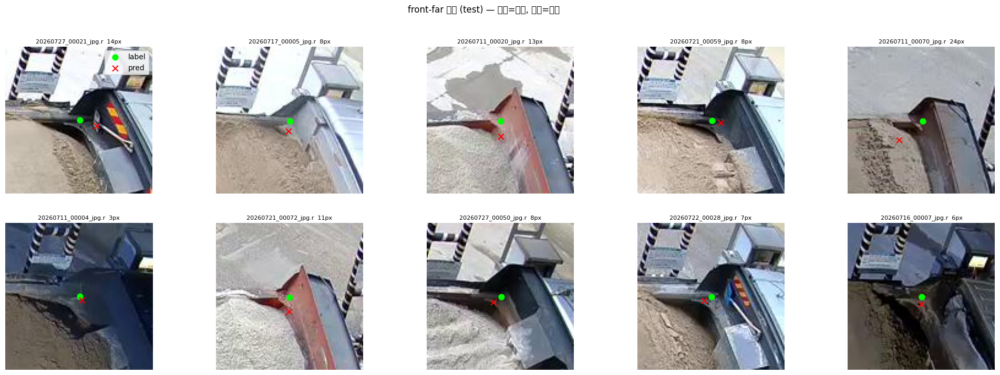

== front-near (test) ==
                file   dx   dy  err  vis
20260727_00021_jpg.r  3.0  8.5  9.0    2
20260717_00005_jpg.r -6.7  0.3  6.7    2
20260711_00020_jpg.r 11.6 14.6 18.6    2
20260721_00059_jpg.r  5.9  4.8  7.6    2
20260711_00070_jpg.r  9.4  3.8 10.1    2
20260711_00004_jpg.r  3.8  3.1  4.9    2
20260721_00072_jpg.r 14.4 13.2 19.6    2
20260727_00050_jpg.r -4.7  2.0  5.1    2
20260722_00028_jpg.r -0.9  0.1  0.9    2
20260716_00007_jpg.r 10.7  1.3 10.7    2
평균 dx=+4.6  dy=+5.2  err=9.3px



/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54869 (\N{HANGUL SYLLABLE HWAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52488 (\N{HANGUL SYLLABLE CO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47197 (\N{HANGUL SYLLABLE ROG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 46972 (\N{HANGUL SYLLABLE RA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/l

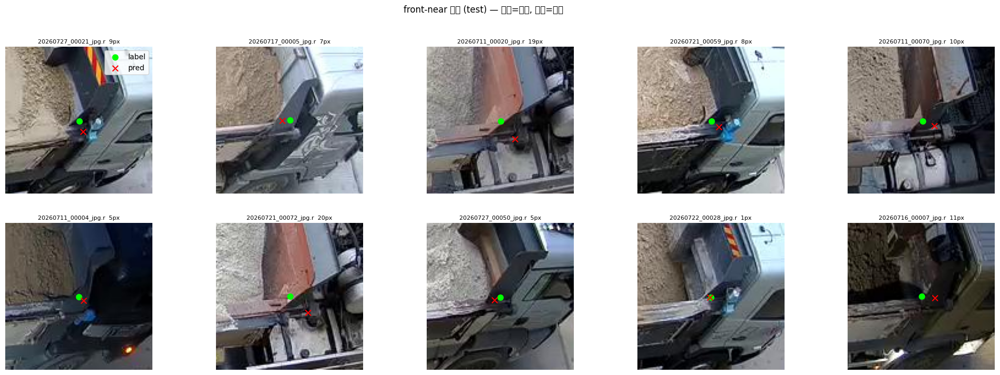

== rear-near (test) ==
                file   dx    dy  err  vis
20260727_00021_jpg.r 15.0  -7.2 16.6    2
20260717_00005_jpg.r 18.5 -18.3 26.0    2
20260711_00020_jpg.r 24.0  -4.7 24.4    2
20260721_00059_jpg.r 21.5 -15.2 26.4    2
20260711_00070_jpg.r 21.4   6.2 22.3    2
20260711_00004_jpg.r 16.8 -10.6 19.9    2
20260721_00072_jpg.r 26.4   3.3 26.6    2
20260727_00050_jpg.r 13.3 -15.3 20.3    2
20260722_00028_jpg.r 16.6  -9.5 19.1    2
20260716_00007_jpg.r 12.2  -5.4 13.3    2
평균 dx=+18.6  dy=-7.7  err=21.5px



/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54869 (\N{HANGUL SYLLABLE HWAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52488 (\N{HANGUL SYLLABLE CO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47197 (\N{HANGUL SYLLABLE ROG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 46972 (\N{HANGUL SYLLABLE RA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/l

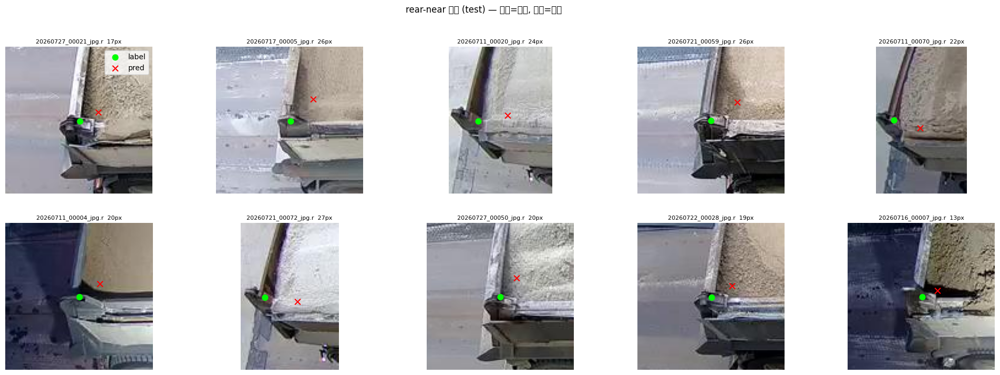

== rear-far (test) ==
                file   dx   dy  err  vis
20260727_00021_jpg.r 10.1 -5.5 11.5    2
20260717_00005_jpg.r  9.1  4.2 10.0    2
20260711_00020_jpg.r 15.6 -9.4 18.3    2
20260721_00059_jpg.r 12.3 -0.4 12.3    2
20260711_00070_jpg.r 10.0 -0.9 10.0    2
20260711_00004_jpg.r  9.9 -2.2 10.1    2
20260721_00072_jpg.r  9.3 -5.5 10.8    2
20260727_00050_jpg.r  4.9  1.1  5.0    2
20260722_00028_jpg.r  6.2  4.9  7.9    2
20260716_00007_jpg.r  3.5  3.7  5.1    2
평균 dx=+9.1  dy=-1.0  err=10.1px



/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54869 (\N{HANGUL SYLLABLE HWAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 52488 (\N{HANGUL SYLLABLE CO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47197 (\N{HANGUL SYLLABLE ROG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 46972 (\N{HANGUL SYLLABLE RA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/l

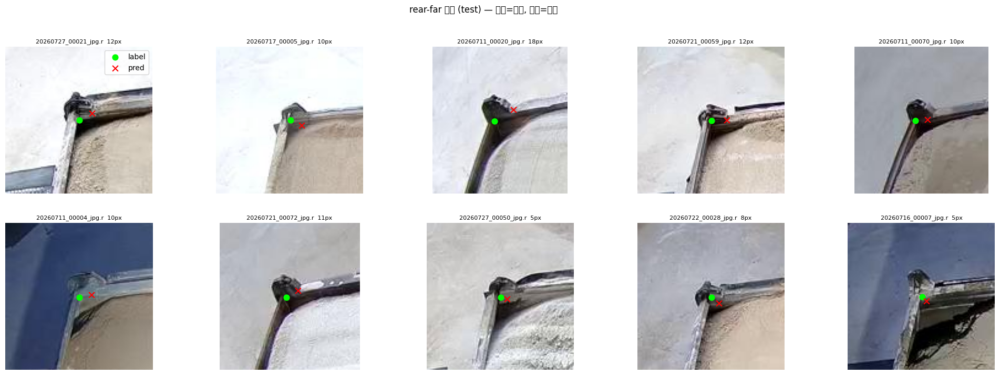

In [10]:
def show_corner(k, split='test', half=60):
    """k: 0=front-far, 1=front-near, 2=rear-near, 3=rear-far"""
    rows, items = [], []
    for _, r in lab[lab.split == split].iterrows():
        gt, vis = read_pose(f'{ROOT}/{split}/labels/{r.file}.txt', r.W, r.H)
        res = best(r.img, verbose=False)[0]
        if len(res.keypoints) == 0: continue
        pred = res.keypoints.xy[res.boxes.conf.argmax()].cpu().numpy()
        d = pred[k] - gt[k]
        rows.append(dict(file=r.file[:20], dx=d[0], dy=d[1], err=np.linalg.norm(d), vis=int(vis[k])))
        items.append((r, gt[k], pred[k]))

    df = pd.DataFrame(rows)
    print(f'== {NAMES[k]} ({split}) ==')
    print(df.round(1).to_string(index=False))
    print(f'평균 dx={df.dx.mean():+.1f}  dy={df.dy.mean():+.1f}  err={df.err.mean():.1f}px\n')

    n = len(items); cols = 5; rws = int(np.ceil(n / cols))
    fig, ax = plt.subplots(rws, cols, figsize=(5 * cols, 4 * rws), squeeze=False)
    for a in ax.ravel(): a.axis('off')
    for a, (r, g, p) in zip(ax.ravel(), items):
        im = cv2.cvtColor(cv2.imread(r.img), cv2.COLOR_BGR2RGB)
        x0, y0 = max(int(g[0]) - half, 0), max(int(g[1]) - half, 0)
        x1, y1 = min(int(g[0]) + half, r.W), min(int(g[1]) + half, r.H)
        a.imshow(im[y0:y1, x0:x1], extent=[x0, x1, y1, y0])
        a.scatter(*g, c='lime', s=60, label='label')
        a.scatter(*p, c='red', s=60, marker='x', label='pred')
        a.set_title(f'{r.file[:20]}  {np.linalg.norm(p - g):.0f}px', fontsize=8)
    ax[0, 0].legend()
    plt.suptitle(f'{NAMES[k]} 확대 ({split}) — 초록=라벨, 빨강=예측'); plt.show()

show_corner(0)   # front-far
show_corner(1)   # front-near
show_corner(2)   # rear-near
show_corner(3)   # rear-far

### (2) 새 모델 추가한 후: 정답라벨/n640/s960/앙상블 결과

104 장 (104면 정상)
== front-far (test) ==
                file  vis  n640  s960  ens
20260727_00021_jpg.r    2  14.2  12.1 13.1
20260717_00005_jpg.r    2   8.0  11.2  7.9
20260711_00020_jpg.r    2  12.6  20.3 16.4
20260721_00059_jpg.r    2   7.6  16.4 11.8
20260711_00070_jpg.r    2  24.4  19.5 21.6
20260711_00004_jpg.r    2   3.4   7.4  5.0
20260721_00072_jpg.r    2  11.5  21.2 16.3
20260727_00050_jpg.r    2   7.7   6.2  4.5
20260722_00028_jpg.r    2   6.7   2.7  3.1
20260716_00007_jpg.r    2   6.0   8.8  6.7
평균 오차(px): {'n640': 10.2, 's960': 12.6, 'ens': 10.6} 



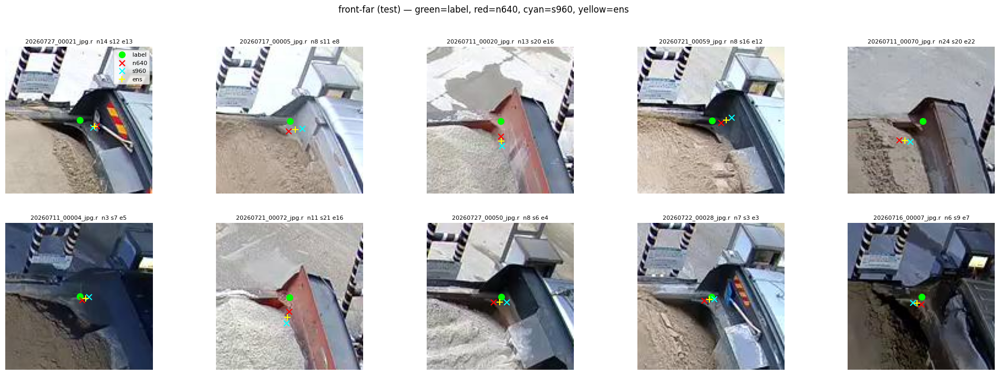

== front-near (test) ==
                file  vis  n640  s960  ens
20260727_00021_jpg.r    2   9.0   9.1  9.0
20260717_00005_jpg.r    2   6.7   1.5  4.1
20260711_00020_jpg.r    2  18.6   8.6 13.3
20260721_00059_jpg.r    2   7.6   9.8  8.5
20260711_00070_jpg.r    2  10.1   2.7  6.4
20260711_00004_jpg.r    2   4.9   2.3  3.6
20260721_00072_jpg.r    2  19.6   9.9 14.2
20260727_00050_jpg.r    2   5.1   1.6  3.3
20260722_00028_jpg.r    2   0.9   4.1  2.3
20260716_00007_jpg.r    2  10.7   5.4  2.7
평균 오차(px): {'n640': 9.3, 's960': 5.5, 'ens': 6.7} 



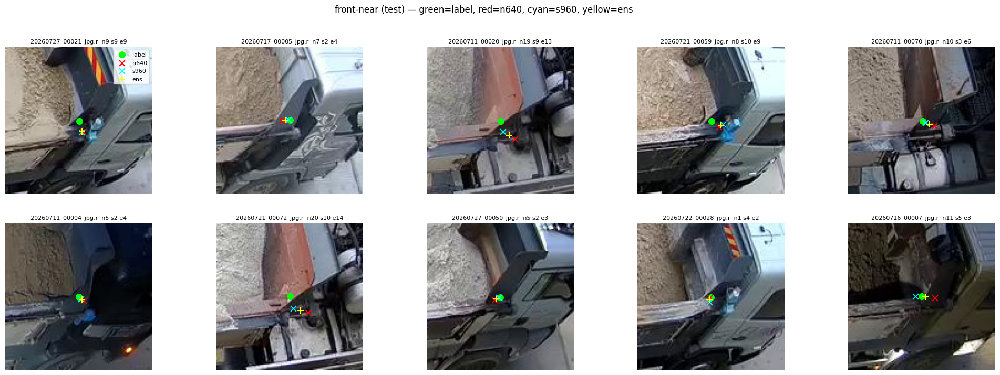

== rear-near (test) ==
                file  vis  n640  s960  ens
20260727_00021_jpg.r    2  16.6   1.5  7.6
20260717_00005_jpg.r    2  26.0   3.5 11.6
20260711_00020_jpg.r    2  24.4  25.0 23.5
20260721_00059_jpg.r    2  26.4   6.9 15.3
20260711_00070_jpg.r    2  22.3  28.0 24.5
20260711_00004_jpg.r    2  19.9   7.1  9.1
20260721_00072_jpg.r    2  26.6  28.7 26.9
20260727_00050_jpg.r    2  20.3   8.5  6.0
20260722_00028_jpg.r    2  19.1  13.7 15.2
20260716_00007_jpg.r    2  13.3  14.3 13.0
평균 오차(px): {'n640': 21.5, 's960': 13.7, 'ens': 15.3} 



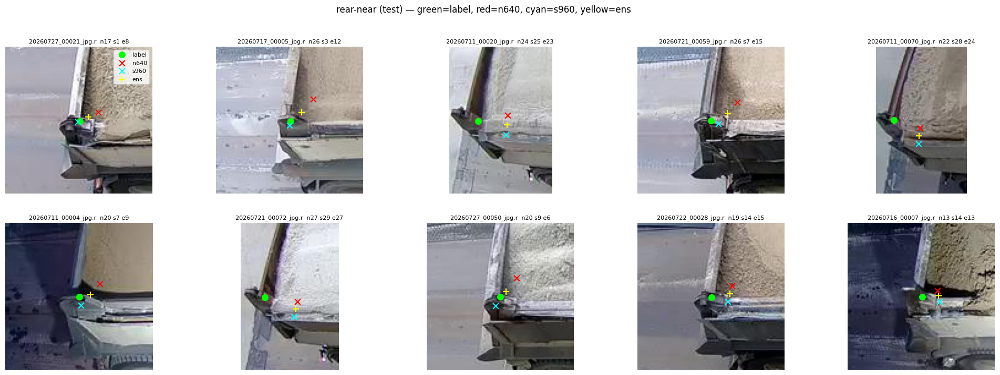

== rear-far (test) ==
                file  vis  n640  s960  ens
20260727_00021_jpg.r    2  11.5   7.4  9.1
20260717_00005_jpg.r    2  10.0  16.9 12.5
20260711_00020_jpg.r    2  18.3  29.8 23.8
20260721_00059_jpg.r    2  12.3  15.4 13.1
20260711_00070_jpg.r    2  10.0  17.5 13.7
20260711_00004_jpg.r    2  10.1   9.4  8.9
20260721_00072_jpg.r    2  10.8  21.8 16.0
20260727_00050_jpg.r    2   5.0  10.6  6.9
20260722_00028_jpg.r    2   7.9  17.3 12.6
20260716_00007_jpg.r    2   5.1  16.7 10.8
평균 오차(px): {'n640': 10.1, 's960': 16.3, 'ens': 12.7} 



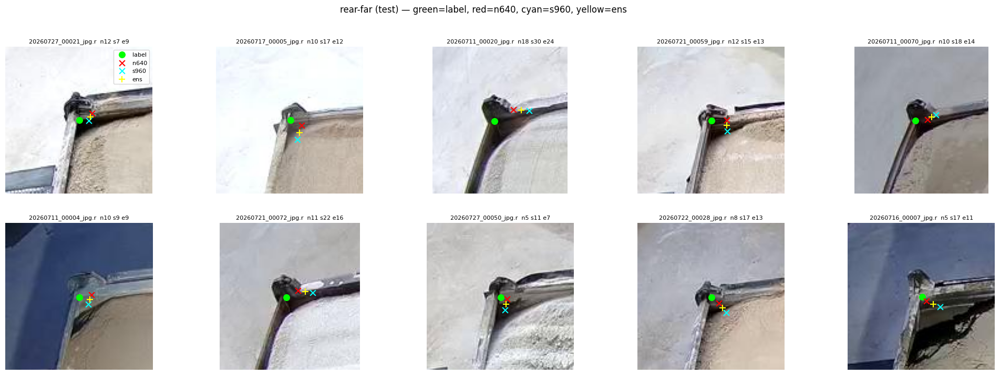

In [17]:
# ===== 꼭짓점 4개 × (라벨 / n640 / s960 / 평균) 한 번에 보기 =====
# 0) 빈 라벨로 지워진 사진을 lab에서도 제거
lab = lab[lab.apply(lambda r: os.path.exists(f'{ROOT}/{r.split}/labels/{r.file}.txt'), axis=1)].reset_index(drop=True)
print(len(lab), '장 (104면 정상)')

# 1) 두 모델
m_old = YOLO(f'{BASE}/yolo/pose_261011/weights/best.pt')        # n640
m_new = YOLO(f'{BASE}/yolo/pose_261011_s960/weights/best.pt')   # s960

def pred4(m, img):
    res = m(img, verbose=False)[0]
    return res.keypoints.xy[res.boxes.conf.argmax()].cpu().numpy() if len(res.keypoints) else None

# 2) 꼭짓점 하나를 확대해서 4종류 점으로 그리기
def show_corner_cmp(k, split='test', half=60):
    """k: 0=front-far, 1=front-near, 2=rear-near, 3=rear-far"""
    rows, items = [], []
    for _, r in lab[lab.split == split].iterrows():
        gt, vis = read_pose(f'{ROOT}/{split}/labels/{r.file}.txt', r.W, r.H)
        a, b = pred4(m_old, r.img), pred4(m_new, r.img)
        if a is None or b is None: continue
        e = (a + b) / 2                                   # 앙상블 = 두 모델 평균
        g = gt[k]
        rows.append(dict(file=r.file[:20], vis=int(vis[k]),
                         n640=np.linalg.norm(a[k] - g), s960=np.linalg.norm(b[k] - g),
                         ens=np.linalg.norm(e[k] - g)))
        items.append((r, g, a[k], b[k], e[k]))

    df = pd.DataFrame(rows)
    print(f'== {NAMES[k]} ({split}) ==')
    print(df.round(1).to_string(index=False))
    print('평균 오차(px):', df[['n640', 's960', 'ens']].mean().round(1).to_dict(), '\n')

    cols = 5; rws = int(np.ceil(len(items) / cols))
    fig, ax = plt.subplots(rws, cols, figsize=(5 * cols, 4 * rws), squeeze=False)
    for a_ in ax.ravel(): a_.axis('off')
    for a_, (r, g, pa, pb, pe) in zip(ax.ravel(), items):
        im = cv2.cvtColor(cv2.imread(r.img), cv2.COLOR_BGR2RGB)
        x0, y0 = max(int(g[0]) - half, 0), max(int(g[1]) - half, 0)
        x1, y1 = min(int(g[0]) + half, r.W), min(int(g[1]) + half, r.H)
        a_.imshow(im[y0:y1, x0:x1], extent=[x0, x1, y1, y0])
        a_.scatter(*g,  c='lime',   s=70, label='label')
        a_.scatter(*pa, c='red',    s=60, marker='x', label='n640')
        a_.scatter(*pb, c='cyan',   s=60, marker='x', label='s960')
        a_.scatter(*pe, c='yellow', s=80, marker='+', label='ens')
        a_.set_title(f'{r.file[:20]}  n{np.linalg.norm(pa-g):.0f} s{np.linalg.norm(pb-g):.0f} e{np.linalg.norm(pe-g):.0f}',
                     fontsize=8)
    ax[0, 0].legend(fontsize=8)
    plt.suptitle(f'{NAMES[k]} ({split}) — green=label, red=n640, cyan=s960, yellow=ens')
    plt.show()

# 3) 실행: test 10장, 꼭짓점 4개
SPLIT = 'test'            # train 라벨 확인하려면 'train'
for k in range(4):
    show_corner_cmp(k, SPLIT)

## 5. 편향 보정 효과 확인
valid 21장에서 꼭짓점별 평균 치우침을 재고, 그만큼 빼서 test 10장으로 효과 보기  
**결과: 보정 효과 매우 좋음**. n640+보정이 전체 7.1px로, 보정 전 12.8px에서 거의 절반으로 줄음. 편향이 우연이 아니라 데이터 전체에서 일관된 성질이라는 의미

In [18]:
# ===== 편향 보정: valid로 치우침 측정 → test로 효과 확인 =====
def preds(split):
    """split의 사진마다 (정답, n640 예측, s960 예측)"""
    out = []
    for _, r in lab[lab.split == split].iterrows():
        gt, _ = read_pose(f'{ROOT}/{split}/labels/{r.file}.txt', r.W, r.H)
        a, b = pred4(m_old, r.img), pred4(m_new, r.img)
        if a is not None and b is not None: out.append((gt, a, b))
    return out

P_val, P_test = preds('valid'), preds('test')

# valid에서 꼭짓점별 평균 치우침 (4, 2)
BIAS = {'n640': np.mean([a - g for g, a, b in P_val], axis=0),
        's960': np.mean([b - g for g, a, b in P_val], axis=0)}
BIAS['ens'] = (BIAS['n640'] + BIAS['s960']) / 2
for k, v in BIAS.items():
    print(k, 'valid 치우침 (dx, dy):', np.round(v, 1).tolist())

def test_err(fn):
    return np.mean([np.linalg.norm(fn(a, b) - g, axis=1) for g, a, b in P_test], axis=0)

res = pd.DataFrame({
    'n640':      test_err(lambda a, b: a),
    'n640+보정': test_err(lambda a, b: a - BIAS['n640']),
    's960':      test_err(lambda a, b: b),
    's960+보정': test_err(lambda a, b: b - BIAS['s960']),
    'ens':       test_err(lambda a, b: (a + b) / 2),
    'ens+보정':  test_err(lambda a, b: (a - BIAS['n640'] + b - BIAS['s960']) / 2),
}, index=NAMES)
res.loc['전체'] = res.mean()
print('\ntest 꼭짓점 오차(px)\n', res.round(1))
print('\n가장 좋은 방식:', res.loc['전체'].idxmin())

n640 valid 치우침 (dx, dy): [[0.7, 7.2], [1.9, 3.8], [17.0, -10.9], [9.4, -0.1]]
s960 valid 치우침 (dx, dy): [[2.1, 7.6], [-3.8, 2.4], [6.7, 4.0], [10.0, 7.8]]
ens valid 치우침 (dx, dy): [[1.4, 7.4], [-1.0, 3.1], [11.8, -3.5], [9.7, 3.8]]

test 꼭짓점 오차(px)
             n640  n640+보정  s960  s960+보정   ens  ens+보정
front-far   10.2      7.7  12.6     10.5  10.6     8.6
front-near   9.3      7.8   5.5      6.4   6.7     6.2
rear-near   21.5      7.7  13.7     10.8  15.3     8.1
rear-far    10.1      5.0  16.3      9.6  12.7     6.7
전체          12.8      7.1  12.0      9.3  11.3     7.4

가장 좋은 방식: n640+보정




## 전체 사진 추론 → 꼭짓점 저장

In [20]:
# ===== 섹션 5: 전체 사진 추론 → 꼭짓점 저장 =====
CHOICE = res.loc['전체'].idxmin()     # 셀 A에서 가장 좋았던 방식 (직접 'ens' 등으로 바꿔도 됨)
print('기본으로 쓸 꼭짓점:', CHOICE)

def pred_full(m, img):
    r = m(img, verbose=False)[0]
    if len(r.keypoints) == 0: return None
    i = r.boxes.conf.argmax()
    return r.keypoints.xy[i].cpu().numpy(), float(r.boxes.conf[i])

FN = {'n640':      lambda a, b: a,
      'n640+보정': lambda a, b: a - BIAS['n640'],
      's960':      lambda a, b: b,
      's960+보정': lambda a, b: b - BIAS['s960'],
      'ens':       lambda a, b: (a + b) / 2,
      'ens+보정':  lambda a, b: (a - BIAS['n640'] + b - BIAS['s960']) / 2}

all_corners = {k: {} for k in FN}
paths = paths = sorted(lab.img.tolist())
for i, ip in enumerate(paths):
    f = os.path.basename(ip)
    pa, pb = pred_full(m_old, ip), pred_full(m_new, ip)
    if pa is None or pb is None: continue
    gap = float(np.linalg.norm(pa[0] - pb[0], axis=1).max())     # 두 모델 차이 = 불확실도
    for k, fn in FN.items():
        all_corners[k][f] = dict(xy=fn(pa[0], pb[0]).tolist(),
                                 box_conf=min(pa[1], pb[1]), gap=gap)
    if i % 50 == 0: print(f'{i}/{len(paths)}')

for k, d in all_corners.items():
    json.dump(d, open(f'{OUT}/corners_{k}.json', 'w'), ensure_ascii=False)
print({k: len(d) for k, d in all_corners.items()}, '장 저장 →', OUT)

corners = all_corners[CHOICE]          # 섹션 6~7이 이 변수를 씀
gaps = pd.Series({f: v['gap'] for f, v in corners.items()}).sort_values(ascending=False)
print('\n두 모델 의견이 가장 갈리는 사진 (px):\n', gaps.head(10).round(1))

기본으로 쓸 꼭짓점: n640+보정
0/104
50/104
100/104
{'n640': 104, 'n640+보정': 104, 's960': 104, 's960+보정': 104, 'ens': 104, 'ens+보정': 104} 장 저장 → /content/drive/MyDrive/capstone/outputs

두 모델 의견이 가장 갈리는 사진 (px):
 20260720_00005_jpg.rf.00f4b072161facf25c2e398b0852ab74.jpg    34.6
20260725_00019_jpg.rf.20849517371e81db37d22b4b91d78a94.jpg    34.2
20260731_00002_jpg.rf.1234d42ead5aca951d7f38cdcfeba05e.jpg    33.9
20260720_00031_jpg.rf.4ca9f4419c0ea0de391bb14655523273.jpg    32.4
20260731_00032_jpg.rf.3c07945bf5a29b83acaccc5db3e8b600.jpg    29.2
20260717_00005_jpg.rf.c19e6f0e5b3d0f5f86cd56b1ebc58921.jpg    29.0
20260713_00049_jpg.rf.c1f326cd68c46aa5e2341f3e683a8811.jpg    28.9
20260727_00050_jpg.rf.d523453e7f3599efc908526bdac28b6e.jpg    28.7
20260730_00003_jpg.rf.b103f54ebe0abf5f17236a7da96aa9cd.jpg    28.6
20260714_00039_jpg.rf.4825f00da115ba9fbf78d296f517c7c6.jpg    28.1
dtype: float64


## 6. 꼭짓점 → Homography → 흙 측정 영역 / 림 기준선
-노란 선: 림 윗면 안쪽 모서리 = 적재함 경계. 모델이 찾은 꼭짓점 4개를 이은 선  
-파란 영역: 깊이를 읽을 안전한 구역. 노란 사각형을 정사영 공간에서 안쪽으로 줄인 것 (앞뒤 6%, 먼 쪽 18%, 가까운 쪽 6%). 사진의 색이나 모양을 보고 정한 게 아니라, 기하학적 규칙으로 정한 영역  
-노랑과 파랑 사이 띠: 벽 안쪽 면, 그림자, 림 테두리가 섞일 수 있는 구역


보정 후 두 모델 차이 (px):
 count    104.0
mean      10.4
std        4.0
min        3.2
25%        7.5
50%        9.9
75%       13.1
max       24.8
dtype: float64


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48372 (\N{HANGUL SYLLABLE BO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


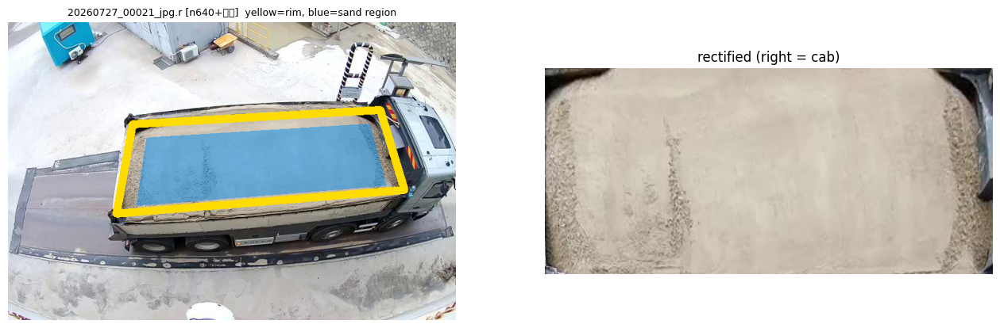

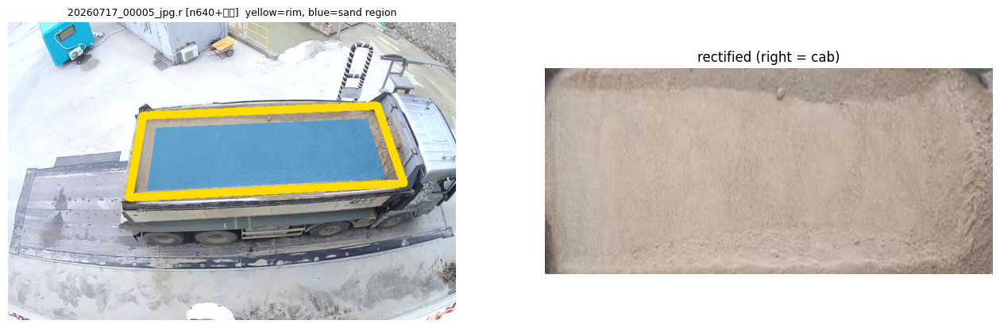

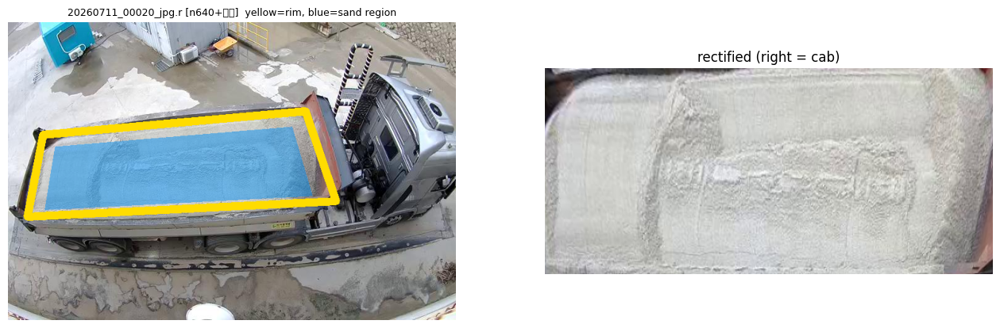

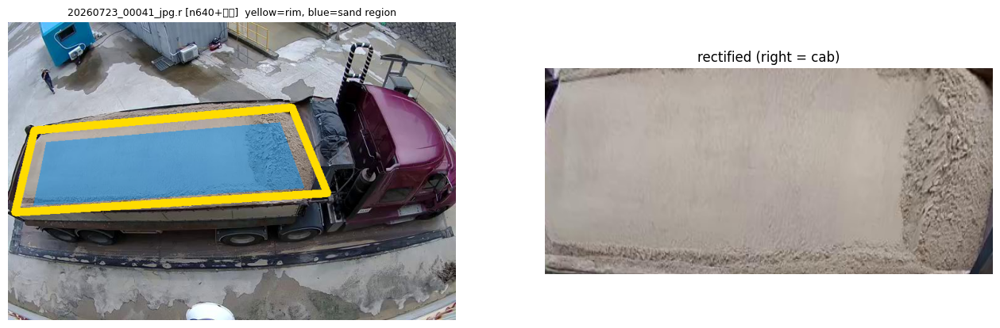

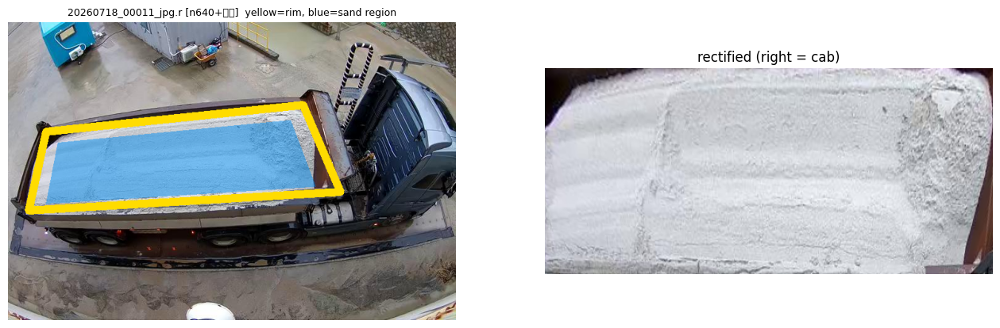

In [22]:
# ===== 섹션 6: 꼭짓점 → 정사영 / 흙 측정 영역 / 림 기준선 =====
IMG_PATH = {os.path.basename(p): p for p in lab.img}      # 파일이름 → 경로 (Roboflow 사진)

OUT_W = 500; OUT_H = int(OUT_W * BED_W / BED_L)
DST = np.array([[OUT_W, 0], [OUT_W, OUT_H], [0, OUT_H], [0, 0]], np.float32)   # 앞-먼, 앞-가까, 뒤-가까, 뒤-먼
M_END, M_FAR, M_NEAR = 0.06, 0.18, 0.06    # 앞뒤벽 / 먼쪽 / 가까운쪽 여백 비율 (그림 보고 조정)
RIM_TH = 11                                 # 림 선 두께(px)

def geometry(xy, W, H):
    c = np.array(xy, np.float32)
    Hm = cv2.getPerspectiveTransform(c, DST)
    rect = np.zeros((OUT_H, OUT_W), np.uint8)
    rect[int(OUT_H * M_FAR):int(OUT_H * (1 - M_NEAR)), int(OUT_W * M_END):int(OUT_W * (1 - M_END))] = 1
    sand = cv2.warpPerspective(rect, np.linalg.inv(Hm), (W, H), flags=cv2.INTER_NEAREST).astype(bool)
    bed  = cv2.fillPoly(np.zeros((H, W), np.uint8), [c.astype(np.int32)], 1).astype(bool)
    rim  = cv2.polylines(np.zeros((H, W), np.uint8), [c.astype(np.int32)], True, 1, thickness=RIM_TH).astype(bool)
    return dict(Hm=Hm, sand=sand, bed=bed, rim=rim, c=c)

def show_geo(fname, key=None):
    key = key or CHOICE
    im = cv2.cvtColor(cv2.imread(IMG_PATH[fname]), cv2.COLOR_BGR2RGB)
    g = geometry(all_corners[key][fname]['xy'], im.shape[1], im.shape[0])
    ov = im.copy()
    ov[g['sand']] = (0.5 * ov[g['sand']] + [0, 70, 120]).astype(np.uint8)
    ov[g['rim']] = [255, 220, 0]
    fig, ax = plt.subplots(1, 2, figsize=(16, 5))
    ax[0].imshow(ov); ax[0].set_title(f'{fname[:20]} [{key}]  yellow=rim, blue=sand region', fontsize=9); ax[0].axis('off')
    ax[1].imshow(cv2.warpPerspective(im, g['Hm'], (OUT_W, OUT_H))); ax[1].set_title('rectified (right = cab)'); ax[1].axis('off')
    plt.show()

# 보정 후 기준으로 두 모델 차이 다시 계산
gap2 = pd.Series({f: np.linalg.norm(np.array(all_corners['n640+보정'][f]['xy']) -
                                    np.array(all_corners['s960+보정'][f]['xy']), axis=1).max()
                  for f in all_corners[CHOICE]}).sort_values(ascending=False)
print('보정 후 두 모델 차이 (px):\n', gap2.describe().round(1))

# 1) test 사진 3장 (모델이 학습 때 안 본 사진)
test_files = [os.path.basename(p) for p in lab[lab.split == 'test'].img][:3]
for f in test_files: show_geo(f)

# 2) 두 모델 차이가 가장 큰 사진 2장 (꼭짓점이 불확실한 사진)
for f in gap2.index[:2]: show_geo(f)

**확인**: 파란 영역에 벽 안쪽 면·옆판이 안 들어가는지. 들어가면 `M_FAR` 등 여백을 키움. 정사영에서 림이 휘어 보이면 렌즈 왜곡 → 그만큼 여백으로 흡수하거나 왜곡 보정 추가.

## 7. Depth — 굴곡 + 림 대비 높이  
  
**1.	Depth만 돌렸을 때**  
사진 전체의 깊이가 나옴. 카메라가 비스듬히 내려다봐서, 원근 때문에 생기는 기울기(가까운 쪽은 높게, 먼 쪽은 낮게)가 흙의 굴곡보다 훨씬 클 수 있음.   

**2.	YOLO-pose + Depth**  
(1)	분석 영역 선택: 꼭짓점 사각형을 안쪽으로 줄여 흙만 있는 측정 영역을 자동으로 만듦. 벽, 옆판, 운전석 제외  
(2)	원근 기울기 제거: 측정 영역에 평면을 맞춰서 빼면 굴곡만 남길 수 있음  
(3)	높이 기준: 꼭짓점을 이은 림 4변으로 기준 평면을 만들어서 "흙이 림보다 높은가 낮은가"를 계산  
(4)	정렬: Homography로 적재함을 위에서 본 직사각형으로 펴서, 트럭 위치가 달라도 같은 틀로 비교  
(5)	자동화: 모든 사진에 같은 방식 적용 가능


config.json:   0%|          | 0.00/1.43k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.34GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/503 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

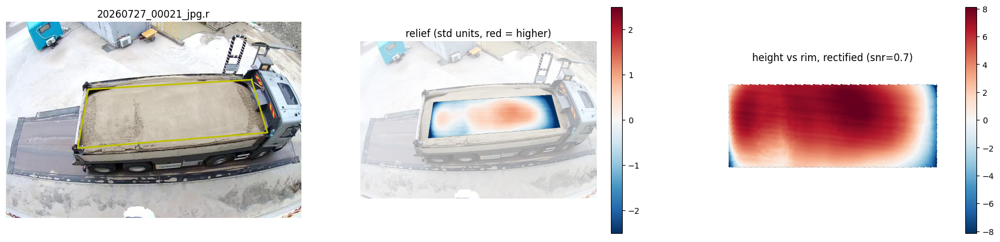

{'file': '20260727_00021_jpg.rf.2c85dd3b53d7158def7a642a985a8bb3.jpg', 'split': 'test', 'relief_std_raw': np.float64(2.513014343399532), 'rim_noise': np.float64(6.121607053838855), 'above_rim_mean': np.float64(4.433808432380387), 'above_rim_snr': np.float64(0.7242883107957654), 'above_rim_p90': np.float64(1.2103885208702276), 'sand_px': 40311, 'gap': 18.028703689575195}


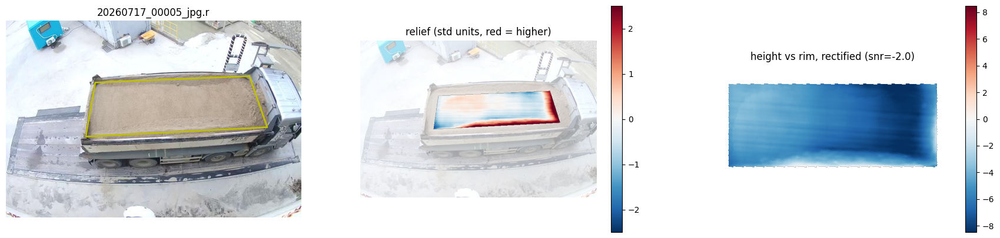

{'file': '20260717_00005_jpg.rf.c19e6f0e5b3d0f5f86cd56b1ebc58921.jpg', 'split': 'test', 'relief_std_raw': np.float64(1.4146053972811123), 'rim_noise': np.float64(2.8722889674606455), 'above_rim_mean': np.float64(-5.663784675533111), 'above_rim_snr': np.float64(-1.9718714724376745), 'above_rim_p90': np.float64(-1.3466328682876219), 'sand_px': 36185, 'gap': 29.009225845336914}


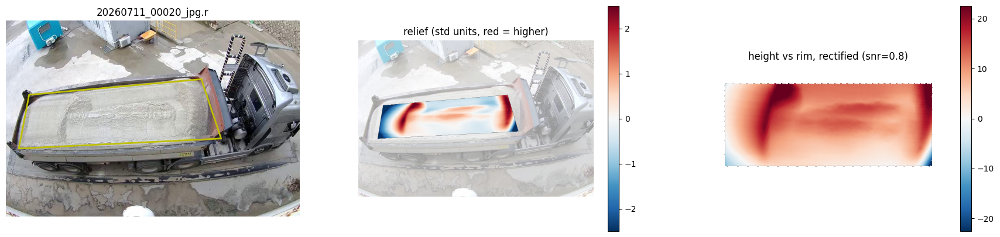

{'file': '20260711_00020_jpg.rf.95791ac6b3968f2c414541b4c3a66b5b.jpg', 'split': 'test', 'relief_std_raw': np.float64(4.332763622351882), 'rim_noise': np.float64(11.685594043852237), 'above_rim_mean': np.float64(9.264503113243512), 'above_rim_snr': np.float64(0.7928140476621763), 'above_rim_p90': np.float64(1.3296453975462978), 'sand_px': 43725, 'gap': 15.613494873046875}


In [23]:
# ===== 섹션 7: Depth — 굴곡(relief) + 림 대비 높이 =====
from transformers import pipeline
depth_pipe = pipeline('depth-estimation', model='depth-anything/Depth-Anything-V2-Large-hf', device=0)

DCACHE = f'{BASE}/depth_cache'; os.makedirs(DCACHE, exist_ok=True)   # 드라이브에 저장 (런타임 끊겨도 유지)

def get_depth(fname, im):
    p = f'{DCACHE}/{fname}.npy'
    if os.path.exists(p): return np.load(p)
    d = depth_pipe(Image.fromarray(im))['predicted_depth'].squeeze().cpu().numpy()
    d = cv2.resize(d, (im.shape[1], im.shape[0])).astype(np.float32)
    np.save(p, d); return d

def fit_plane(d, region, iters=3, keep=0.7):
    """평면 ax+by+c 맞추기. 잔차 큰 30%를 버리고 다시 맞춤 (림 선에 흙·벽이 섞여도 덜 흔들림)"""
    ys, xs = np.nonzero(region & np.isfinite(d))
    for _ in range(iters):
        A = np.c_[xs, ys, np.ones_like(xs)]
        coef, *_ = np.linalg.lstsq(A, d[ys, xs], rcond=None)
        r = np.abs(d[ys, xs] - A @ coef)
        m = r <= np.quantile(r, keep)
        xs, ys = xs[m], ys[m]
    yy, xx = np.mgrid[:d.shape[0], :d.shape[1]]
    return coef[0] * xx + coef[1] * yy + coef[2]

def analyze(fname, key=None, show=True):
    key = key or CHOICE
    im = cv2.cvtColor(cv2.imread(IMG_PATH[fname]), cv2.COLOR_BGR2RGB)
    H, W = im.shape[:2]
    g = geometry(all_corners[key][fname]['xy'], W, H)
    d = get_depth(fname, im)
    s = g['sand']

    raw_relief = d - fit_plane(d, s)                       # 흙 영역 평면 제거 = 굴곡
    relief = raw_relief / raw_relief[s].std()
    rim_plane = fit_plane(d, g['rim'])                     # 림 4변으로 기준 평면
    above_rim = d - rim_plane                              # +: 림보다 카메라 쪽(높음)
    rim_noise = np.abs(d[g['rim']] - rim_plane[g['rim']]).std() + 1e-6

    out = dict(file=fname, split=lab.set_index(lab.img.map(os.path.basename)).split.get(fname),
               relief_std_raw=raw_relief[s].std(), rim_noise=rim_noise,
               above_rim_mean=above_rim[s].mean(), above_rim_snr=above_rim[s].mean() / rim_noise,
               above_rim_p90=np.percentile(above_rim[s], 90) / rim_noise,      # 가장 높은 부분
               sand_px=int(s.sum()), gap=all_corners[key][fname]['gap'])

    if show:
        fig, ax = plt.subplots(1, 3, figsize=(22, 5))
        ax[0].imshow(im); ax[0].plot(*np.vstack([g['c'], g['c'][:1]]).T, 'y-', lw=2)
        ax[0].set_title(fname[:20]); ax[0].axis('off')
        ax[1].imshow(im, alpha=0.4)
        i1 = ax[1].imshow(np.where(s, relief, np.nan), cmap='RdBu_r', vmin=-2.5, vmax=2.5)
        ax[1].set_title('relief (std units, red = higher)'); ax[1].axis('off'); plt.colorbar(i1, ax=ax[1])
        ar = cv2.warpPerspective(np.where(s, above_rim, np.nan).astype(np.float32), g['Hm'],
                                 (OUT_W, OUT_H), flags=cv2.INTER_NEAREST, borderValue=np.nan)
        v = np.nanpercentile(np.abs(ar), 98)
        i2 = ax[2].imshow(ar, cmap='RdBu_r', vmin=-v, vmax=v)
        ax[2].set_title(f'height vs rim, rectified (snr={out["above_rim_snr"]:.1f})'); ax[2].axis('off')
        plt.colorbar(i2, ax=ax[2]); plt.show()
    return out

# 1) 섹션 6에서 본 사진들로 먼저 눈으로 확인
for f in test_files: print(analyze(f))

**해석 메모**
- `above_rim_snr`: 흙이 림보다 얼마나 위/아래인지를 림 평면 노이즈로 나눈 값. 사진끼리 비교 가능한 '높이' 지표 1순위 → 계근값과 상관 확인
- `corner_conf_min`이 낮은 사진은 꼭짓점이 틀렸을 가능성 → 특징 분석에서 제외하거나 눈으로 확인
- 상대 깊이라 cm 단위 아님. 다음 단계: 림 높이·지면(계근대 철판) 두 평면으로 스케일 맞추기